In [1]:
import polars as pl
import seaborn_polars as snl
import re

In [2]:
from tool_extraction import SEED, artifacts, artifact_siblings, repos, mining_runs


In [3]:
artifact_siblings.collect_schema()

Schema([('repo_full_name', String),
        ('artifact_path', String),
        ('entry_name', String),
        ('entry_type', String),
        ('entry_size', Int64),
        ('entry_sha', String),
        ('content', String),
        ('content_fetched', Int64),
        ('skipped_reason', String)])

In [4]:
(
    artifact_siblings
    .select("content_fetched", "content")
    .filter(pl.col("content_fetched") == 0)
    .select("content")
    .describe()
)

statistic,content
str,str
"""count""","""0"""
"""null_count""","""1036908"""
"""mean""",null
"""std""",null
"""min""",null
"""25%""",null
"""50%""",null
"""75%""",null
"""max""",null


In [5]:
(
    artifact_siblings
    .select("content_fetched", "content")
    .filter(pl.col("content_fetched") == 1)
    .select("content")
    .describe()
)

statistic,content
str,str
"""count""","""3497752"""
"""null_count""","""10641"""
"""mean""",null
"""std""",null
"""min""",""""""
"""25%""",null
"""50%""",null
"""75%""",null
"""max""","""🧵 New deep dive: The Future of…"


In [6]:
(
    artifact_siblings
    .select("content_fetched", "content")
    .filter(pl.col("content_fetched") == 2)
    .select("content")
    .describe()
)

statistic,content
str,str
"""count""","""0"""
"""null_count""","""2719564"""
"""mean""",null
"""std""",null
"""min""",null
"""25%""",null
"""50%""",null
"""75%""",null
"""max""",null


In [7]:
labels = {0: "directory", 1: "text_stored", 2: "text_absent"}

fetched = (
    artifact_siblings.group_by("content_fetched")
    .agg(
        pl.len().alias("n"),
        pl.col("content").str.strip_chars().replace("", None).is_not_null().sum().alias("with_text"),
    )
    .with_columns(pl.col("content_fetched").replace_strict(labels).alias("status"))
    .sort("content_fetched")
    .collect()
)
fetched.head()

content_fetched,n,with_text,status
i64,u32,u32,str
0,1036908,0,"""directory"""
1,3508393,3486179,"""text_stored"""
2,2719564,0,"""text_absent"""


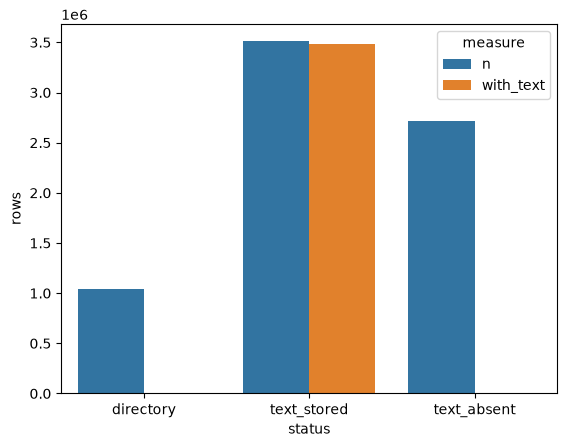

In [8]:
plot_df = fetched.unpivot(
    on=["n", "with_text"],
    index="status",
    variable_name="measure",
    value_name="rows",
)
snl.barplot(plot_df, x="status", y="rows", hue="measure")

So only content_fetched == 1 has content, and even these has null values.

In [9]:
artifact_siblings_with_content = (
    artifact_siblings
    .select("entry_sha", "content", "repo_full_name", "artifact_path", "entry_name", "content_fetched")
    .filter(pl.col("content_fetched") == 1)
    .with_columns(pl.col("content").str.strip_chars().replace("", None))
    .filter(pl.col("content").is_not_null())
    .drop("content_fetched")
)
artifact_siblings_with_content.head().collect()

entry_sha,content,repo_full_name,artifact_path,entry_name
str,str,str,str,str
"""5043b7196d53053e4b1013403d3b64…","""{ ""version"": 1, ""id"": ""mid…","""0-AI-UG/cate""","""skills/cate-theme/SKILL.md""","""examples/midnight-ember.cate-t…"
"""0cb2e2103def3abbf7a717668394c2…","""{ ""version"": 1, ""id"": ""pap…","""0-AI-UG/cate""","""skills/cate-theme/SKILL.md""","""examples/paper-light.cate-them…"
"""f11253fd93ebee1109f0f1b9c7e44a…","""{ ""$schema"": ""http://json-sc…","""0-AI-UG/cate""","""skills/cate-theme/SKILL.md""","""theme.schema.json"""
"""ab25f27ebcecca37d6b26f26640da2…","""# Coder Delegation Safety Har…","""0-CYBERDYNE-SYSTEMS-0/FFT_nano""","""skills/runtime/fft-coder-ops/S…","""references/safety.md"""
"""c92d9039aff7a84290926083326830…","""#!/usr/bin/env bash set -euo p…","""0-CYBERDYNE-SYSTEMS-0/FFT_nano""","""skills/runtime/fft-debug/SKILL…","""scripts/collect-debug-snapshot…"


In [10]:
content = pl.col("content")
valid = content.str.json_path_match("$").is_not_null()

kinds = (
    artifact_siblings_with_content.select(
        pl.when(valid & content.str.starts_with("{")).then(pl.lit("json_object"))
        .when(valid & content.str.starts_with("[")).then(pl.lit("json_array"))
        .when(valid).then(pl.lit("json_other"))
        .otherwise(pl.lit("free_text"))
        .alias("kind")
    )
    .group_by("kind")
    .len()
    .collect()
)

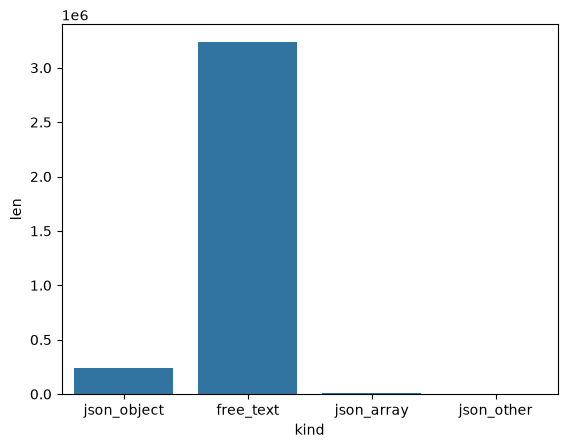

In [11]:
snl.barplot(kinds, x="kind", y="len")

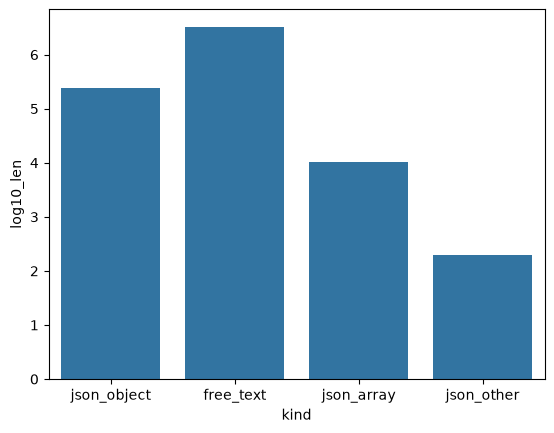

In [12]:
plot = kinds.with_columns(pl.col("len").log10().alias("log10_len"))
snl.barplot(plot, x="kind", y="log10_len")

## Gliner Entity

In [13]:
from gliner import GLiNER

model = GLiNER.from_pretrained("urchade/gliner_small-v2.1")

/home/nichmorgan/Projects/nau/msr-data-challenge-2027/scripts/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/nichmorgan/Projects/nau/msr-data-challenge-2027/scripts/.venv/lib/python3.13/site-packages/huggingface_hub/utils/_validators.py:190: UserWarning: The `resume_download` argument is deprecated and ignored in `snapshot_download`. Downloads always resume whenever possible.
  warnings.warn(


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

In [14]:
# Every column gets the same seed so the sampled rows stay aligned.
sample = artifact_siblings_with_content.select(pl.all().sample(n=500, seed=SEED)).collect()
sample.head(3)

entry_sha,content,repo_full_name,artifact_path,entry_name
str,str,str,str,str
"""69301b4ae010905ede5a063048ca53…","""#!/usr/bin/env python3 """"""Appl…","""lightspeedwp/.github""","""agents/client-website-discover…","""scripts/comments_apply_patch.p…"
"""0da363e9cb3014d24a6c4fa922c8dd…","""export function normalizeZulip…","""niyazmft/openclaw-zulip-bridge""","""SKILL.md""","""src/normalize.ts"""
"""0d92ada056f8b2004a03ec48e53cbd…","""""""""Unit tests for linkedin.py …","""yagyesh-bobde/xai-personalize-…","""SKILL.md""","""tests/test_linkedin.py"""


In [15]:
MAX_LENGTH = 384
MAX_WORDS_CONTEXT = 5
HIT_THRESHOLD = 0.8
HIT_LABELS = ["tool", "organization"]
HIT_DTYPES = pl.Struct({
    "snippet": pl.List(pl.String),
    "entity": pl.String,
    "label": pl.String,
    "score": pl.Float64,
})

def get_snippet(text: str, entity: str) -> list[str]:
    pattern = re.compile(rf"(?<!\w){re.escape(entity)}(?!\w)")
    snippets = []
    for match in pattern.finditer(text):
        before = text[: match.start()].split()
        after = text[match.end() :].split()
        highlighted = f"[{match.group()}]"
        snippet = " ".join(before[-MAX_WORDS_CONTEXT:] + [highlighted] + after[:MAX_WORDS_CONTEXT])
        if len(before) > MAX_WORDS_CONTEXT:
            snippet = "..." + snippet
        if len(after) > MAX_WORDS_CONTEXT:
            snippet = snippet + "..."
        snippets.append(snippet)
    return snippets

def extract(text: str) -> dict:
    clipped = (text or "")[:MAX_LENGTH]
    return [
        {
            "entity": ent["text"],
            "label": ent["label"],
            "score": ent["score"],
            "snippet": get_snippet(clipped, ent["text"]),
        }
        for ent in model.predict_entities(clipped, HIT_LABELS, threshold=HIT_THRESHOLD)
    ]

hits = (
    sample.lazy()
    .select("entry_sha", "content")
    .with_columns(
        pl.col("content")
            .map_elements(extract, return_dtype=pl.List(HIT_DTYPES))
            .alias("hits")
    )
    .explode("hits")
    .unnest("hits")
    .select("entry_sha", "snippet", "entity", "label", "score")    
)

with pl.Config(fmt_str_lengths=20_000):
    display(hits.head(20).collect())

entry_sha,snippet,entity,label,score
str,list[str],str,str,f64
"""0d92ada056f8b2004a03ec48e53cbd1f068a4dae""","[""""""""Unit tests for [linkedin] .py pure helpers. Run with..."", ""...import sys sys.path.insert(0, os.path.dirname(os.path.dirname(__file__))) import [linkedin] as L # noqa: E402...""]","""linkedin""","""organization""",0.98536
"""0d92ada056f8b2004a03ec48e53cbd1f068a4dae""","[""...linkedin.py pure helpers. Run with [pytest] (`python3 -m pytest tests/test_linkedin.py -v`)..."", ""...Run with pytest (`python3 -m [pytest] tests/test_linkedin.py -v`) or directly (`python3..."", ""...or directly (`python3 tests/test_linkedin.py`) when [pytest] is unavailable. """""" import os...""]","""pytest""","""tool""",0.9485
"""0d92ada056f8b2004a03ec48e53cbd1f068a4dae""","[""...linkedin.py pure helpers. Run with [pytest] (`python3 -m pytest tests/test_linkedin.py -v`)..."", ""...Run with pytest (`python3 -m [pytest] tests/test_linkedin.py -v`) or directly (`python3..."", ""...or directly (`python3 tests/test_linkedin.py`) when [pytest] is unavailable. """""" import os...""]","""pytest""","""tool""",0.946572
"""0d92ada056f8b2004a03ec48e53cbd1f068a4dae""","[""...linkedin.py pure helpers. Run with [pytest] (`python3 -m pytest tests/test_linkedin.py -v`)..."", ""...Run with pytest (`python3 -m [pytest] tests/test_linkedin.py -v`) or directly (`python3..."", ""...or directly (`python3 tests/test_linkedin.py`) when [pytest] is unavailable. """""" import os...""]","""pytest""","""tool""",0.936272
"""0d92ada056f8b2004a03ec48e53cbd1f068a4dae""","[""""""""Unit tests for [linkedin] .py pure helpers. Run with..."", ""...import sys sys.path.insert(0, os.path.dirname(os.path.dirname(__file__))) import [linkedin] as L # noqa: E402...""]","""linkedin""","""organization""",0.983199
…,…,…,…,…
"""e674f7086fa7426e60d8d3823c74ce6cfa83ccde""","[""#!/bin/bash # [meeting-prep] /scripts/prep.sh — Research attendees for..."", ""...CONFIG & ARGS --- PREP_DIR=""${PREP_DIR:-$HOME/.config/ [meeting-prep] }"" CONFIG_FILE=""$PREP_DIR/config.json"" HISTORY_FILE=""$PREP_DIR/brief-history.json"" LOG_FILE=""$PREP_DIR/prep-log.json"" BRIEFS_DIR=""$PREP_DIR/briefs""...""]","""meeting-prep""","""tool""",0.858133
"""e674f7086fa7426e60d8d3823c74ce6cfa83ccde""","[""#!/bin/bash # [meeting-prep] /scripts/prep.sh — Research attendees for..."", ""...CONFIG & ARGS --- PREP_DIR=""${PREP_DIR:-$HOME/.config/ [meeting-prep] }"" CONFIG_FILE=""$PREP_DIR/config.json"" HISTORY_FILE=""$PREP_DIR/brief-history.json"" LOG_FILE=""$PREP_DIR/prep-log.json"" BRIEFS_DIR=""$PREP_DIR/briefs""...""]","""meeting-prep""","""tool""",0.809411
"""bf48e8b8fec43bc4b6fc6ee326dcf4fffe1eaea8""","[""..."""""" Subdomain Enumeration Pipeline with [Subfinder] Automates subdomain discovery, validation, and...""]","""Subfinder""","""tool""",0.917386


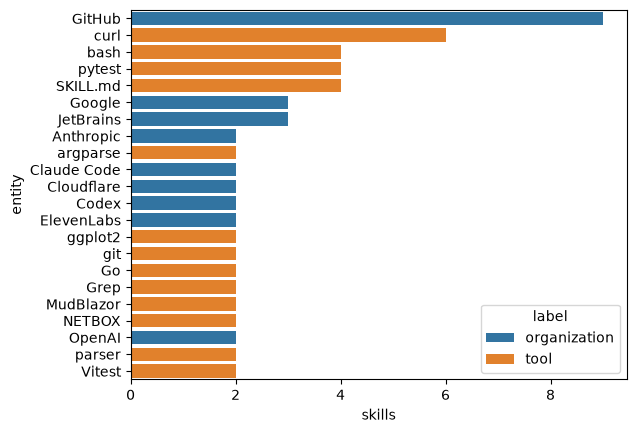

In [16]:
top = (
    hits.with_columns(pl.col("entity").str.to_lowercase().alias("key"))
    .group_by("key")
    .agg(
        pl.col("entry_sha").n_unique().alias("skills"),
        pl.col("label").mode().sort().first().alias("label"),
        pl.col("entity").mode().sort().first().alias("entity"),
    )
    .filter(pl.col("skills") >= 2)
    .sort(["skills", "key"], descending=[True, False])
    .collect()
)
snl.barplot(top, y="entity", x="skills", hue="label", order=top["entity"].to_list())